In [2]:
from jupyter_bioacoustic import BioacousticAnnotator
from tools import MapHandler
from tools import analysis
from importlib import reload

In [3]:
from IPython.display import Markdown, display
import pandas as pd
from ipyleaflet import Map
import requests

---

# INPUT DATA

**LOAD MODEL PREDICTIONS**

In [4]:
df = pd.read_csv('data/dev-review.csv')
display(Markdown(f'**MODEL RUN DATA (size: {df.shape[0]})**'))
df.sample(3)

**MODEL RUN DATA (size: 1500)**

,id,common_name,scientific_name,confidence,rank,start_time,end_time,audio_path,county,lat,lon
267,268,Common raven,Corvus corax,0.762,2,12027.36,12039.36,audio/test3.flac,Del Norte,41.59477,-123.99379
1439,1440,Woodpecker spp. drum,NaN,0.764,1,2188.24,2200.24,audio/test1.flac,Monterey,36.28326,-120.23505
668,669,Canada goose,Branta canadensis,0.938,3,6122.30,6134.30,NaN,Stanislaus,37.51440,-121.15630


**GET CA COUNTY BOUNDARIES**

In [5]:
all_counties = requests.get(
    "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json"
).json()
ca_counties = {
    "type": "FeatureCollection",
    "features": [f for f in all_counties["features"] if f["id"].startswith("06")]
}
print(f"{len(df)} rows, {len(ca_counties['features'])} counties")

1500 rows, 58 counties


---

## DATA SELECTION

The jupyter-lab environment allows us select data using code, and using interactive methods like the map below. Select county interest or draw a polygon to select a specific region of interest.

In [6]:
m = Map(center=(37.5, -119.5), zoom=6, layout={'height': '600px'})
handler = MapHandler(df, region_data=ca_counties, region_column='county', polygon_tool=True)
handler.add_to(m)
m

loading shapely...


Map(center=[37.5, -119.5], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_o…

**INSPECT SELECTED DATA**

In [11]:
if handler.selected is not None:
    display(Markdown('---'))
    display(Markdown('**CONFIDENCE STATS**'))
    handler.describe('common_name', 'confidence')
    display(Markdown('---'))
    display(Markdown('**SAMPLE DATA**'))
    display(handler.selected.sample(3))
else:
    print('No data selected')

---

**CONFIDENCE STATS**

Region: San Joaquin — 28 points


confidence                                              \
                           count      mean       std    min      25%     50%   
common_name                                                                    
Canada goose                 1.0  0.746000       NaN  0.746  0.74600  0.7460   
Common nighthawk boom        8.0  0.847375  0.116020  0.725  0.73600  0.8375   
Dog barks                    2.0  0.186500  0.065761  0.140  0.16325  0.1865   
Downy woodpecker call        1.0  0.397000       NaN  0.397  0.39700  0.3970   
Great horned owl             2.0  0.366500  0.048790  0.332  0.34925  0.3665   
Sooty grouse                12.0  0.827667  0.100225  0.671  0.75500  0.8335   
Woodpecker spp. drum         2.0  0.681000  0.050912  0.645  0.66300  0.6810   

                                       
                           75%    max  
common_name                            
Canada goose           0.74600  0.746  
Common nighthawk boom  0.94975  0.988  
Dog barks              0.20975  0.233  
Downy woodpecker call  0.39700  0.397  
Great horned owl       0.38375  0.401  
Sooty grouse           0.87600  0.999  
Woodpecker spp. drum   0.69900  0.717

---

**SAMPLE DATA**

,id,common_name,scientific_name,confidence,rank,start_time,end_time,audio_path,county,lat,lon
1047,1048,Dog barks,NaN,0.233,3,11592.44,11604.44,audio/test1.flac,San Joaquin,38.27295,-121.19723
722,723,Common nighthawk boom,Chordeiles minor,0.738,1,5466.89,5478.89,audio/test1.flac,San Joaquin,37.82759,-121.23989
321,322,Common nighthawk boom,Chordeiles minor,0.985,1,4068.89,4080.89,audio/test1.flac,San Joaquin,38.19081,-120.94894


---

# BioacousticAnnotator

Here we run BioacousticAnnotator, but only use the data-selected with the interactive map above

In [12]:
handler.selected

,id,common_name,scientific_name,confidence,rank,start_time,end_time,audio_path,county,lat,lon
24,25,Sooty grouse,Dendragapus fuliginosus,0.999,1,13269.32,13281.32,audio/test2.flac,San Joaquin,38.27436,-121.19673
93,94,Downy woodpecker call,Dryobates pubescens,0.397,1,954.55,966.55,audio/test3.flac,San Joaquin,38.04176,-121.43066
185,186,Common nighthawk boom,Chordeiles minor,0.938,2,1433.36,1445.36,audio/test1.flac,San Joaquin,38.02825,-121.54512
277,278,Woodpecker spp. drum,NaN,0.645,3,7713.58,7725.58,audio/test2.flac,San Joaquin,38.06031,-121.21270
321,322,Common nighthawk boom,Chordeiles minor,0.985,1,4068.89,4080.89,audio/test1.flac,San Joaquin,38.19081,-120.94894
339,340,Common nighthawk boom,Chordeiles minor,0.781,1,8074.17,8086.17,NaN,San Joaquin,37.64705,-121.04168
395,396,Sooty grouse,Dendragapus fuliginosus,0.869,1,12666.68,12678.68,audio/test1.flac,San Joaquin,38.12412,-121.58451
516,517,Dog barks,NaN,0.140,2,9440.39,9452.39,audio/test2.flac,San Joaquin,38.14238,-121.37559
564,565,Great horned owl,Bubo virginianus,0.401,1,13940.97,13952.97,audio/test1.flac,San Joaquin,37.94589,-121.11203
612,613,Sooty grouse,Dendragapus fuliginosus,0.756,2,197.40,209.40,audio/test3.flac,San Joaquin,37.95540,-121.55762


In [13]:
ba = BioacousticAnnotator(
    data=handler.selected,
    config='annotator_config/config/model_review_and_geoanalysis.yaml',
    output='outputs/review-data.csv',
    reviewer_name='brookie',
    review_date=20260413
)
ba.open()

<IPython.core.display.Javascript object>

In [39]:
validated_data = ba.output()
if validated_data is not None and len(validated_data) > 0:
    display(Markdown('---'))
    display(Markdown(f'**OUTPUT DATA (size: {validated_data.shape[0]})**'))
    sample_size = min(10, len(validated_data))
    display(validated_data.sample(sample_size))
else:
    print('No validated data yet')

---

**OUTPUT DATA (size: 757)**

,detection_id,start_time,end_time,is_valid,notes,verified_common_name,verification_confidence,reviewer_name,review_date
687,688.0,11571.07,11583.07,yes,Strong vocalization,NaN,NaN,alex,20260418.0
293,294.0,13179.43,13191.43,yes,NaN,NaN,NaN,casey,20260417.0
219,220.0,8128.78,8140.78,yes,NaN,NaN,NaN,jordan,20260415.0
297,298.0,203.31,215.31,yes,NaN,NaN,NaN,brookie,20260416.0
529,530.0,10826.34,10838.34,no,Wrong habitat for species,Common nighthawk boom,high,jordan,20260414.0
339,340.0,8074.17,8086.17,no,NaN,Olive-sided flycatcher,low,brookie,20260419.0
396,397.0,8875.9,8887.90,no,NaN,Common nighthawk call,medium,jordan,20260418.0
60,61.0,9222.4,9234.40,no,NaN,Canada goose,medium,alex,20260420.0
269,270.0,7302.81,7314.81,yes,Faint call,NaN,NaN,jordan,20260419.0
537,538.0,2690.43,2702.43,yes,NaN,NaN,NaN,alex,20260414.0


---

# ANALYSIS

Now that we have verified data we can run our analysis in the same environment. No Jupyter-Annotator Bounce! Below we show

1. Species Counts for both model detections and validated data
2. County Level Analysis: Accuracy and Diversity
3. County Level Maps of Dominant Species and Model Accuracy

### SPECIES COUNTS

---

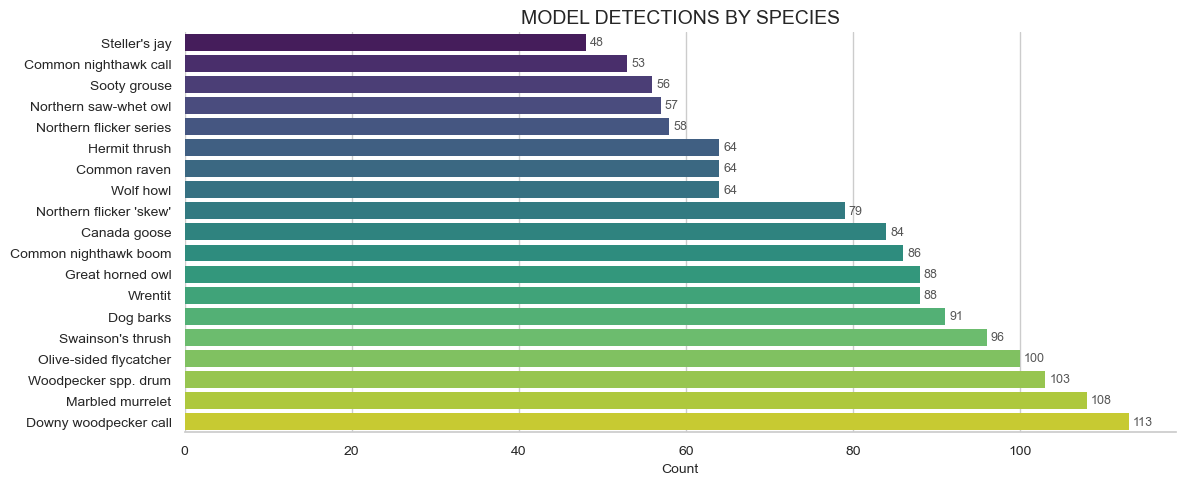

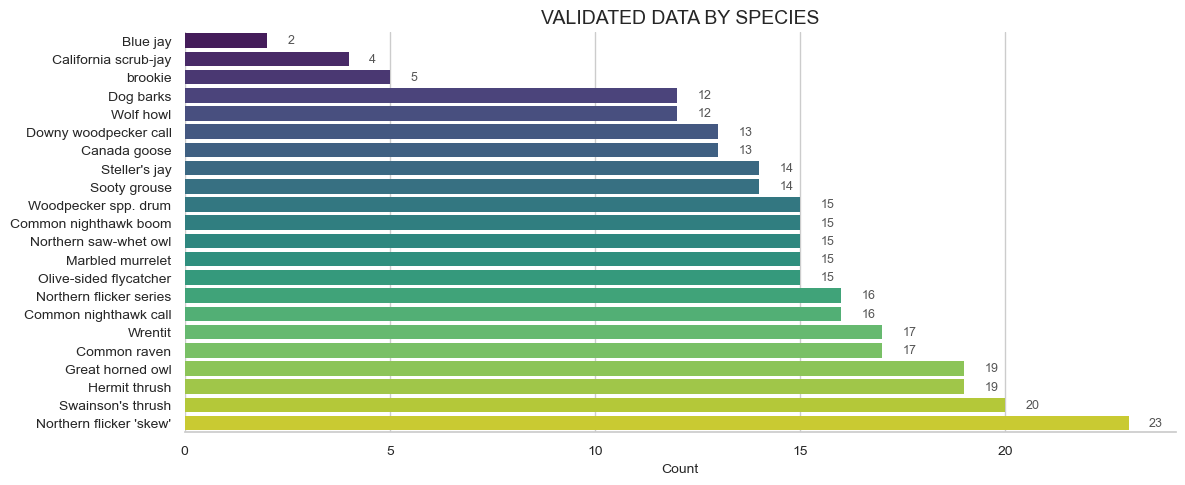

---

In [40]:
%matplotlib inline
analysis = reload(analysis)
display(Markdown('---'))
analysis.species_histogram(df, title='Model Detections by Species')
if validated_data is not None and len(validated_data) > 0:
    analysis.species_histogram(validated_data, title='Validated Data by Species', column='verified_common_name')
display(Markdown('---'))

### COUNTY LEVEL ANALYSIS

---

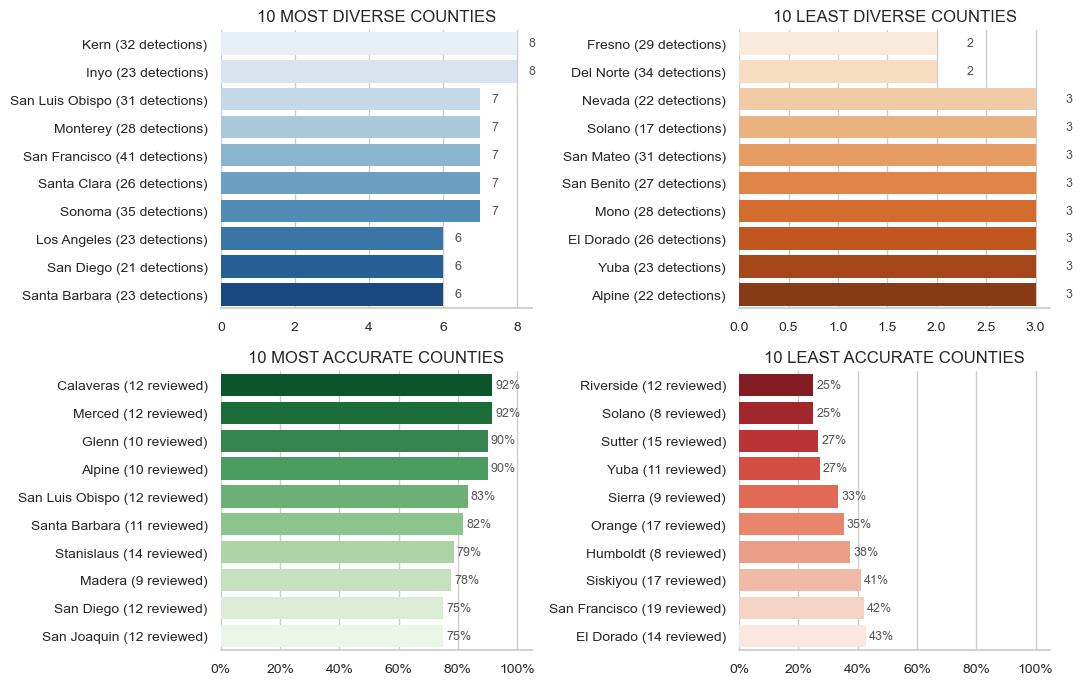

---

In [41]:
%matplotlib inline
analysis = reload(analysis)
display(Markdown('---'))
if validated_data is not None and len(validated_data) > 0:
    analysis.county_distributions(df, validated_data)
else:
    print('Need validated data for county analysis')
display(Markdown('---'))

### COUNTY LEVEL MAPS

In [42]:
MAP_CENTER = (37.5, -119.5)
ZOOM = 6
LAYOUT = {'height': '600px'}

In [43]:
%matplotlib inline
analysis = reload(analysis)

# DOMINANT SPECIES MAP
display(Markdown('---'))
display(Markdown(f'**DOMINANT SPECIES BY COUNTY**'))
m = Map(center=MAP_CENTER, zoom=ZOOM, layout=LAYOUT)
layer, info = analysis.county_species_map(m, df, ca_counties)
display(m, info)
display(Markdown('---'))

# ACCURACY MAP
if validated_data is not None and len(validated_data) > 0:
    display(Markdown(f'**ACCURACY BY COUNTY**'))
    m2 = Map(center=MAP_CENTER, zoom=ZOOM, layout=LAYOUT)
    layer, info = analysis.county_accuracy_map(m2, df, output_df=validated_data, county_geojson=ca_counties)
    display(m2, info)
else:
    print('Need validated data for accuracy map')
display(Markdown('---'))

---

**DOMINANT SPECIES BY COUNTY**

Map(center=[37.5, -119.5], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_o…

Output()

---

**ACCURACY BY COUNTY**

Map(center=[37.5, -119.5], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_o…

Output()

---